# Day05 — error analysis

## D5-01 — проверенный validation reference

Цель: загрузить сохранённые predictions выбранного Day04 candidate без fit, CV или оценки test. Входы — Day02 processed/provenance, Day03 manifest/reference, Day04 selection/config/predictions/metrics/provenance.

SHA-256 проверяет байты artifacts, а semantic checks — IDs, порядок, labels и параметры. Join выполняется one-to-one по `source_row_id`: одинаковая длина таблиц не гарантирует соответствия предложений. Все validation строки сохраняются; `errors` — только фильтр, не новая выборка для настройки модели.

In [1]:
from pathlib import Path
import sys
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src/finnews_sentiment").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src/finnews_sentiment").is_dir():
    raise RuntimeError("Run from the project root or notebooks directory")
sys.path.insert(0, str(ROOT / "src"))

from finnews_sentiment.models.error_analysis import load_validation_analysis

analysis = load_validation_analysis(ROOT)
print("Candidate:", analysis.candidate_id)
print("Selection:", analysis.selection_path.relative_to(ROOT))
print("Parameters:", analysis.parameters)

Candidate: linear_svc
Selection: reports/day04/selection.json
Parameters: {'tfidf': {'max_features': 5000, 'ngram_range': [1, 2], 'analyzer': 'word', 'lowercase': False, 'stop_words': None, 'min_df': 1, 'max_df': 1.0, 'use_idf': True, 'smooth_idf': True, 'sublinear_tf': False, 'norm': 'l2', 'token_pattern': '(?u)\\b\\w\\w+\\b', 'strip_accents': None}, 'classifier': {'C': 1.0, 'class_weight': None, 'dual': 'auto', 'fit_intercept': True, 'intercept_scaling': 1, 'loss': 'squared_hinge', 'max_iter': 5000, 'multi_class': 'ovr', 'penalty': 'l2', 'random_state': 42, 'tol': 0.0001, 'verbose': 0}}


In [2]:
n_valid = len(analysis.table)
n_errors = len(analysis.errors)
print("Table shape:", analysis.table.shape)
print(f"N_valid={n_valid}; errors={n_errors}; error rate={n_errors / n_valid:.2%}")
display(analysis.table.head())
display(analysis.errors.head())

Table shape: (553, 9)
N_valid=553; errors=84; error rate=15.19%


,source_row_id,group_id,text,text_clean,true_label_id,pred_label_id,true_label,pred_label,is_error
0,2,2,"For the last quarter of 2010 , Componenta 's n...","for the last quarter of 2010 , componenta 's n...",2,2,positive,positive,False
1,3,3,"In the third quarter of 2010 , net sales incre...","in the third quarter of 2010 , net sales incre...",2,2,positive,positive,False
2,11,11,Consolidated net sales increased 16 % to reach...,consolidated net sales increased 16 % to reach...,2,2,positive,positive,False
3,16,16,"Lifetree was founded in 2000 , and its revenue...","lifetree was founded in 2000 , and its revenue...",2,1,positive,neutral,True
4,28,28,The fair value of the property portfolio doubl...,the fair value of the property portfolio doubl...,2,1,positive,neutral,True


,source_row_id,group_id,text,text_clean,true_label_id,pred_label_id,true_label,pred_label,is_error
3,16,16,"Lifetree was founded in 2000 , and its revenue...","lifetree was founded in 2000 , and its revenue...",2,1,positive,neutral,True
4,28,28,The fair value of the property portfolio doubl...,the fair value of the property portfolio doubl...,2,1,positive,neutral,True
8,59,59,The combination of all services enabling us to...,the combination of all services enabling us to...,2,1,positive,neutral,True
10,72,72,Biohit already services many current Genesis c...,biohit already services many current genesis c...,2,1,positive,neutral,True
20,114,114,Finnish Okmetic that manufactures and processe...,finnish okmetic that manufactures and processe...,2,1,positive,neutral,True


### Интерпретация и самопроверка

Таблица `(N_valid, 9)` сохраняет raw/clean text и исходный manifest order. `pred_label_id` явно получен из `selected_pred_label_id`. Показаны первые реальные ошибки в исходном порядке; это проверка загрузки, ручной разбор остаётся D5-03. Доля ошибок равна `1 − accuracy`, но не заменяет macro F1: частый neutral может доминировать в accuracy. Нулевое число ошибок допустимо.

1. Почему одинаковой длины таблиц недостаточно для alignment?
2. Почему переставленные reference predictions вызывают ошибку, хотя join по ID технически возможен?
3. Какие проверки защищают от изменения данных и от пересечения text groups?
4. Почему найденные ошибки не дают права менять текущую модель перед test?

## D5-02 — confusion matrix и направления ошибок

Цель: превратить проверенные validation labels `(N_valid,)` в counts и row-normalized матрицы `(3, 3)`, шесть направленных пар и per-class metrics. Модель не вызывается: используются сохранённые predictions D5-01.

Строки = **true**, столбцы = **predicted**, фиксированный порядок `negative / neutral / positive`. Counts показывают число строк. Нормировка `M[i, j] / support[i]` показывает долю исходов **внутри истинного класса**; диагональ равна recall, а precision использует сумму столбца. При support=0 строка нулевая и подписана как absent.

Сумма counts = N_valid; диагональ = верные ответы; off-diagonal = ошибки. Все сохранённые строки, включая duplicate groups, учитываются по одному разу: они не становятся независимыми наблюдениями.

Validation: N=553; accuracy=0.848101; macro F1=0.805961
Counts: rows=true, columns=predicted


pred_label,negative,neutral,positive
true_label,,,
negative,47,15,5
neutral,3,326,15
positive,4,42,96


Normalized: count / true support


pred_label,negative,neutral,positive
true_label,,,
negative,0.701493,0.223881,0.074627
neutral,0.008721,0.947674,0.043605
positive,0.028169,0.295775,0.676056


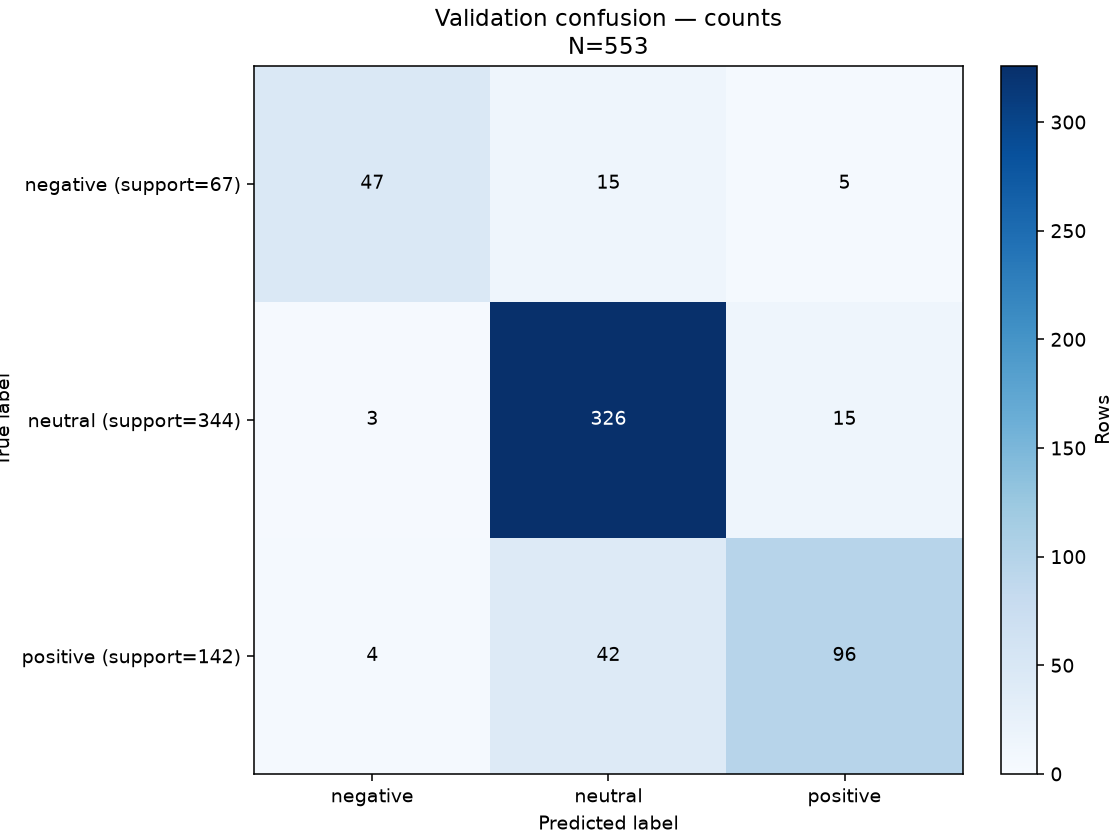

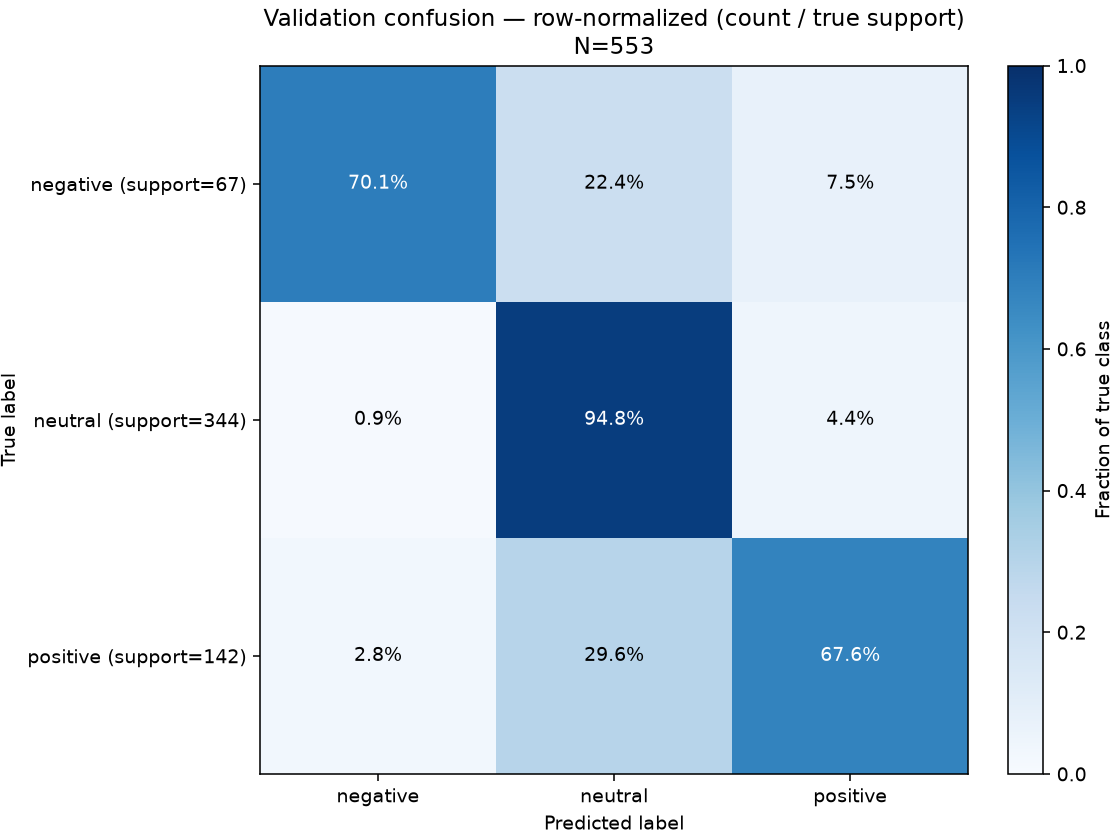

In [3]:
from finnews_sentiment.models.confusion import build_validation_confusion, save_validation_confusion
from IPython.display import Image

confusion = build_validation_confusion(analysis.table)
confusion_paths = save_validation_confusion(confusion, ROOT / "reports/day05")
print(f"Validation: N={confusion.metrics.n_samples}; accuracy={confusion.metrics.accuracy:.6f}; macro F1={confusion.metrics.macro_f1:.6f}")
print("Counts: rows=true, columns=predicted")
display(confusion.counts)
print("Normalized: count / true support")
display(confusion.normalized)
display(Image(filename=str(confusion_paths["counts_png"])))
display(Image(filename=str(confusion_paths["normalized_png"])))

In [4]:
print("Per-class metrics: zero_division=0; labels=[0, 1, 2]")
display(confusion.per_class)
print("Six directed error pairs; fraction_of_true = count / true_support")
display(confusion.pairs)
print("Saved Day05 artifacts:")
for artifact_name, artifact_path in confusion_paths.items():
    print(artifact_name, artifact_path.relative_to(ROOT))

Per-class metrics: zero_division=0; labels=[0, 1, 2]


,class_id,class_name,precision,recall,f1,support,predicted_count
0,0,negative,0.870370,0.701493,0.776860,67,54
1,1,neutral,0.851175,0.947674,0.896836,344,383
2,2,positive,0.827586,0.676056,0.744186,142,116


Six directed error pairs; fraction_of_true = count / true_support


,true_label,pred_label,count,true_support,fraction_of_true
0,negative,neutral,15,67,0.223881
1,negative,positive,5,67,0.074627
2,neutral,negative,3,344,0.008721
3,neutral,positive,15,344,0.043605
4,positive,negative,4,142,0.028169
5,positive,neutral,42,142,0.295775


Saved Day05 artifacts:
counts_csv reports/day05/validation_confusion_counts.csv
counts_png reports/day05/validation_confusion_counts.png
normalized_csv reports/day05/validation_confusion_normalized.csv
normalized_png reports/day05/validation_confusion_normalized.png
pairs_csv reports/day05/confusion_pairs.csv


### Интерпретация и самопроверка

В validation 553 строки: 469 верных ответов и 84 ошибки. Самое частое направление — **positive → neutral: 42/142 = 29,58%** истинных positive. Обратное направление neutral → positive: **15/344 = 4,36%**. Сравнение counts без этих denominators скрыло бы различие долей.

Negative → neutral: **15/67 = 22,39%**; обратное neutral → negative: **3/344 = 0,87%**. Negative → positive: 5/67 = 7,46%; positive → negative: 4/142 = 2,82%. Среди всех шести пар positive → neutral наиболее частая и по count, и по доле истинного класса.

Recall: negative **70,15%**, neutral **94,77%**, positive **67,61%**. Accuracy **84,81%** при macro F1 **0,805961**: neutral содержит 344/553 строк, а macro F1 даёт каждому из трёх классов одинаковый вес. Все классы присутствуют; нулевых support здесь нет. Это описательные validation результаты; они не объясняют причины ошибок и не используются для изменения параметров. Ручной разбор предложений остаётся D5-03.

1. Чем true negative → predicted neutral отличается от обратной пары? Какие у них denominators?
2. Почему большой count ошибок neutral сам по себе не означает худший recall?
3. Почему диагональ нормированной по строкам матрицы равна recall, а не precision?
4. Что означает нулевая строка при support=0, и почему это не идеальное качество?
5. Почему counts duplicate rows не равны числу независимых наблюдений?